# 02 · Network and line performance

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammedelsayed741996-blip/berlin-data-portfolio/blob/main/mobility/bus-network-demand-planning/notebooks/02_network_and_line_performance.ipynb)

Which lines carry people efficiently, which run with too many seats and which turn customers away?
The main KPI is load factor: passenger-km divided by seat-km over the whole line. Average peak
load would hide a line that is full for 40 km and empty for the next 200.

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

REPO = "https://github.com/mohammedelsayed741996-blip/berlin-data-portfolio.git"
PROJECT = "mobility/bus-network-demand-planning"

if "google.colab" in sys.modules:
    if not Path("/content/berlin-data-portfolio").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/berlin-data-portfolio"], check=True)
    os.chdir(f"/content/berlin-data-portfolio/{PROJECT}")
else:
    here = Path.cwd()
    while not (here / "src" / "bus_network").exists() and here != here.parent:
        here = here.parent
    os.chdir(here)

sys.path.insert(0, str(Path.cwd() / "src"))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
from IPython.display import Image, display
print("Project folder:", Path.cwd().name)

Project folder: bus-network-demand-planning


In [2]:
from bus_network import config as C, data, validation as V, analysis as A, planning as P, reporting as R, db

if not any(Path("data").glob("*.csv*")):
    data.save(data.generate(), Path("data"))
tables = data.load(Path("data"))
LAST_12M = ("2025-10-01", "2026-09-30")
print({name: len(df) for name, df in tables.items()})
trips = V.clean_trips(tables)

{'bookings': 80380, 'line_stops': 73, 'od_monthly': 6138, 'operations': 80180, 'partners': 9, 'stops': 33, 'timetable': 80, 'truth_demand': 80320}


In [3]:
k = A.line_kpis(trips, LAST_12M)
k["route"] = k["line"].map(A.route_label)
k[["line", "route", "pax", "load_factor", "peak_load_factor", "sold_out_share", "contribution_margin"]].sort_values("load_factor")

,line,route,pax,load_factor,peak_load_factor,sold_out_share,contribution_margin
16,L040,Cologne - Amsterdam (via Duesseldorf),180062,0.2371,0.7206,0.1823,-0.1157
13,L031,Munich - Zurich,12197,0.3452,0.3452,0.0000,-0.4397
11,L023,Hamburg - Amsterdam,13426,0.3806,0.3806,0.0028,-0.2797
17,L041,Cologne - Amsterdam (via Aachen),54164,0.4917,0.8384,0.3618,0.4816
0,L010,"Berlin - Munich (via Leipzig, Nuremberg)",173353,0.5116,0.7003,0.1334,0.4790
21,L045,"Leipzig - Dortmund (via Goettingen, Kassel)",39455,0.5242,0.7552,0.2193,0.1944
12,L030,"Munich - Frankfurt (via Stuttgart, Karlsruhe)",125352,0.5274,0.7141,0.1388,0.4966
10,L022,Hamburg - Copenhagen,19101,0.5422,0.5422,0.0473,0.1647
14,L032,Munich - Prague (via Regensburg),46486,0.5518,0.7092,0.1458,0.5190
1,L011,"Berlin - Vienna (via Dresden, Prague)",223111,0.6313,0.8356,0.3703,0.5958


Two kinds of problem show up. L023 and L031 are short of passengers on every segment and lose money
after bus costs. L040 Cologne to Amsterdam is different: its busiest segment is 72% full on average,
but over the whole route the load factor is 24%. Most passengers ride the short Cologne to
Duesseldorf stretch and the buses run nearly empty to Amsterdam. At the other end, L016 Berlin to
Warsaw sells out on about half its departures.

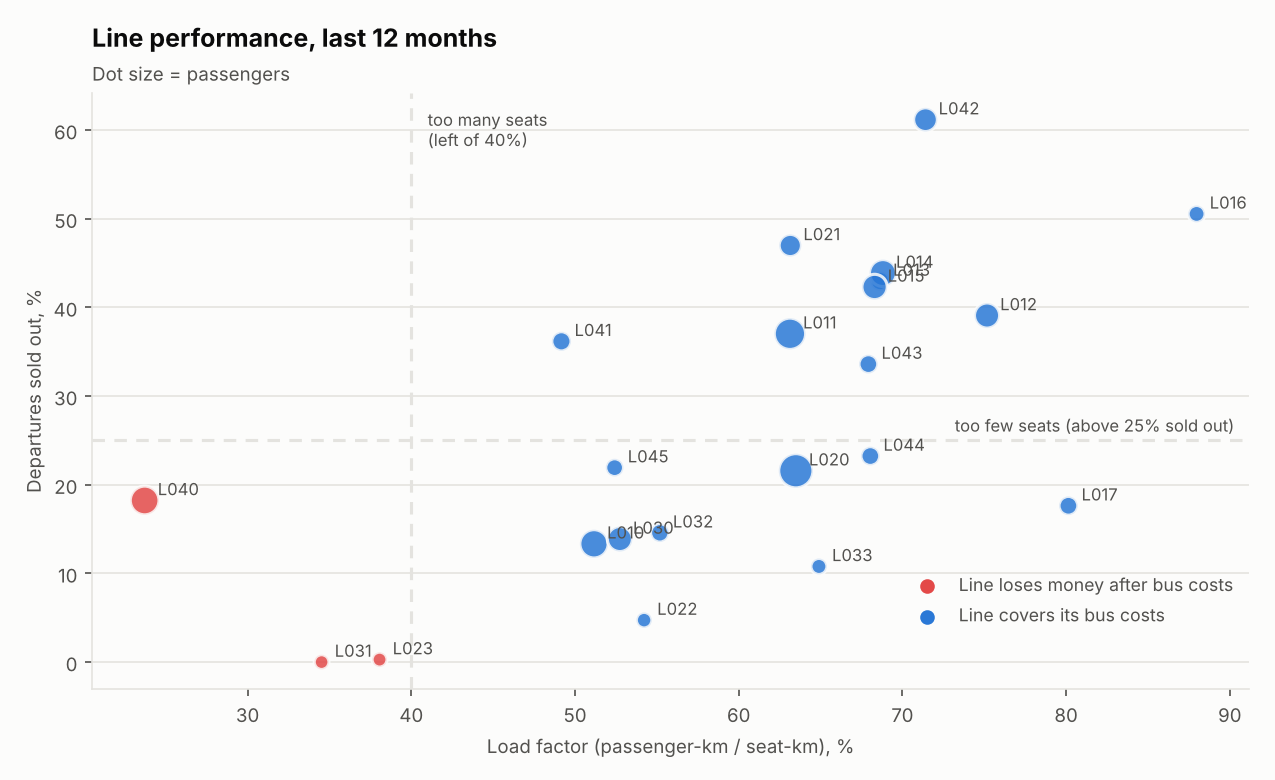

In [4]:
R.plot_line_matrix(k, Path("outputs/figures/line_matrix.png"))
display(Image("outputs/figures/line_matrix.png"))

## The network as a graph

Cities are nodes and segments are edges, weighted by average passengers on board. Betweenness
centrality shows which cities hold the network together: a disruption there affects the most
journeys.

In [5]:
G = A.network_graph(trips, LAST_12M)
A.hub_table(G).head(8)

,city,lines,direct_destinations,betweenness
0,Frankfurt,6,6,0.394
1,Berlin,8,8,0.237
2,Cologne,5,4,0.222
3,Kassel,2,4,0.198
4,Hanover,3,6,0.196
5,Dortmund,3,4,0.151
6,Nuremberg,2,4,0.146
7,Wuerzburg,1,2,0.135


## Where demand has no direct line

A gravity model (passengers rise with both cities' populations and fall with distance) is fitted on
the city pairs that already have a direct connection. It is then applied to pairs that do not, to
rank candidates for new lines.

In [6]:
grav = A.fit_gravity(tables["od_monthly"], LAST_12M)
print("R² on served pairs:", round(grav["r2"], 3), "| population elasticity:", round(grav["beta"][1], 2),
      "| distance elasticity:", round(grav["beta"][2], 2))
gaps = A.demand_gaps(grav, G)
gaps.head(8)

R² on served pairs: 0.953 | population elasticity: 0.75 | distance elasticity: -1.17


,origin,destination,road_km,expected_pax_per_day_each_way,current_best_path_km,detour_pct,changes_needed
0,Hamburg,Leipzig,358.1,26.9,492.0,0.37,1
1,Hamburg,Rostock,183.4,26.1,548.0,1.99,1
2,Leipzig,Prague,246.6,26.0,528.0,1.14,1
3,Berlin,Duesseldorf,582.0,25.7,658.0,0.13,1
4,Vienna,Warsaw,677.6,24.2,1284.0,0.89,1
5,Frankfurt,Duesseldorf,223.7,24.0,229.0,0.02,1
6,Frankfurt,Dortmund,216.4,23.9,275.0,0.27,1
7,Berlin,Stuttgart,623.6,23.7,724.0,0.16,1


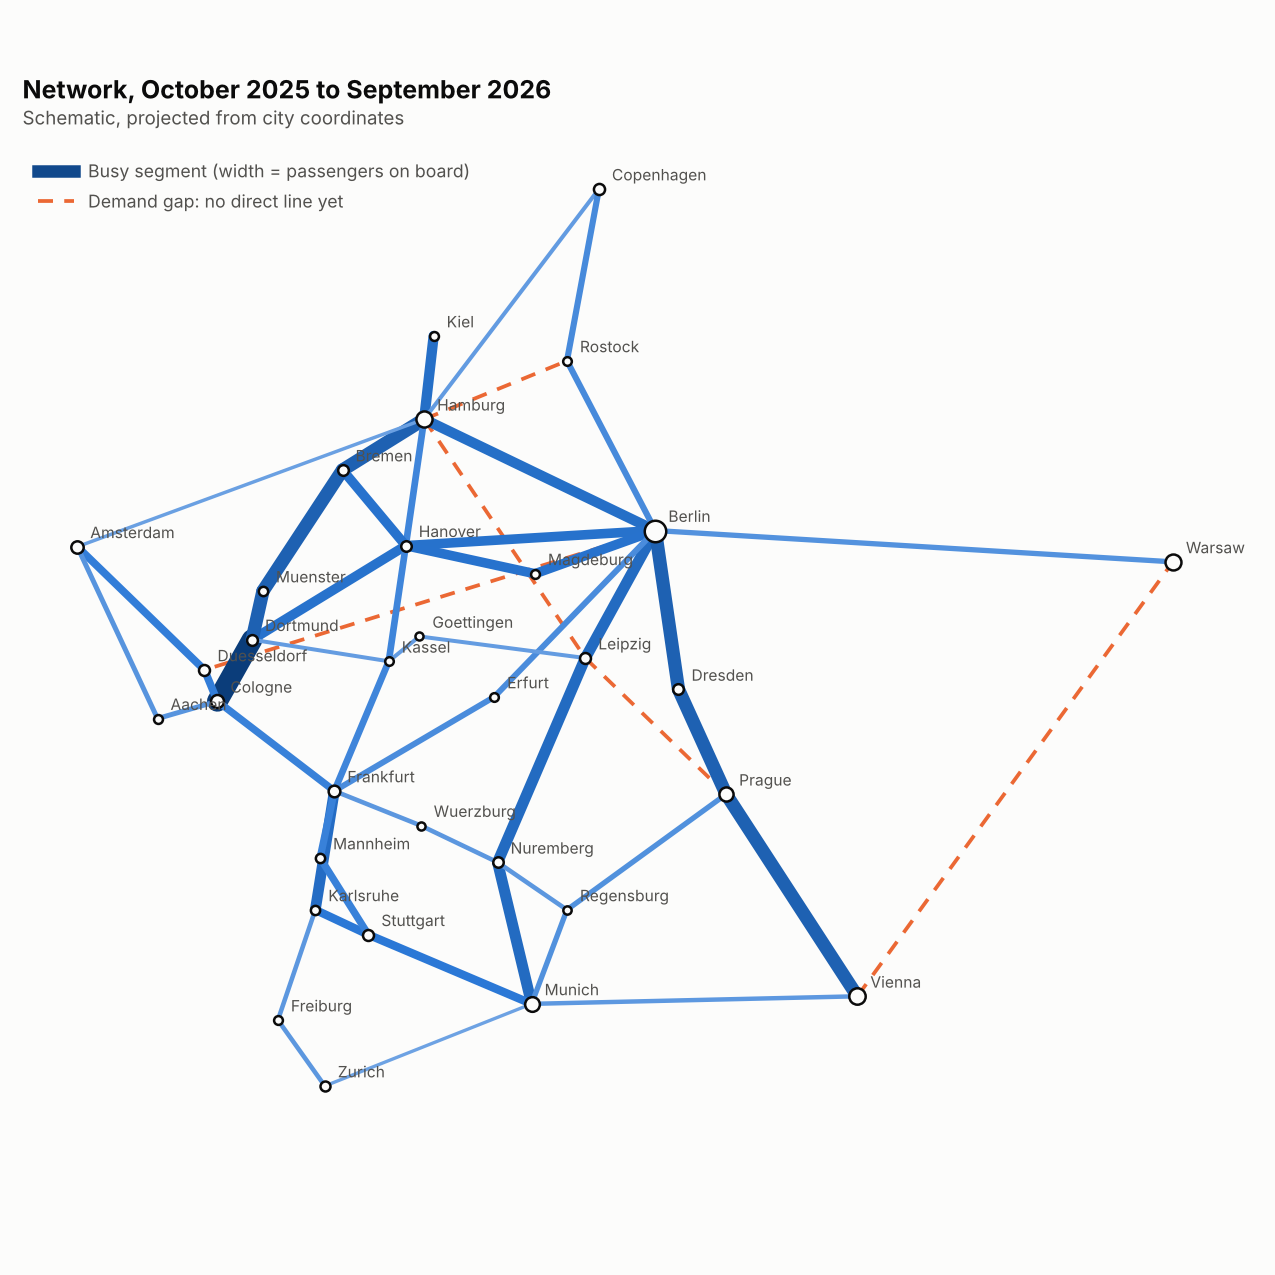

In [7]:
R.plot_network_map(G, gaps, Path("outputs/figures/network_map.png"))
display(Image("outputs/figures/network_map.png"))

The same network is exported as `outputs/network.geojson`, which GitHub draws as an interactive map,
and as `outputs/network_map.html` with Leaflet and OpenStreetMap tiles.

In [8]:
geo = R.geojson(G, gaps, Path("outputs/network.geojson"))
R.html_map(geo, Path("outputs/network_map.html"))
print(geo.stat().st_size // 1024, "KB GeoJSON written")

28 KB GeoJSON written
